# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ

**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации

**Датасет:** House Prices — Advanced Regression Techniques

**Выполнил:** Бреславская Ирина Владимировна

**Группа:** ПКТб-23-1

**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/breslavskayaira/ml-course-breslavskaya

**Путь к модулю:** `module-2-house-prices/notebook.ipynb`

**Дата сдачи:** 2026-10-13


## Введение

**Задача:** регрессия — предсказать цену продажи дома (`SalePrice`), непрерывную величину в долларах. Цены в датасете варьируются от $34 900 до $755 000.

**ML-проект для регрессии** — это последовательность этапов: сбор данных → разведочный анализ (EDA) → предобработка (пропуски, выбросы, кодирование) → feature engineering → обучение моделей → оценка качества → интерпретация → сохранение и деплой модели.

**Почему регрессия, а не классификация:** целевая переменная `SalePrice` является непрерывной, а не дискретной. Задача состоит в предсказании точной цены, а не отнесении объекта к классу.

**Почему выбран датасет House Prices:**  
Датасет содержит 79 объясняющих переменных, описывающих почти все аспекты жилых домов в Эймсе, Айова. Он включает числовые, порядковые и номинальные признаки, имеет пропуски, выбросы и скошенное распределение целевой переменной — что делает его отличным полигоном для отработки полного цикла предобработки и регрессии.

**Какая метрика важнее:**  
В задачах регрессии цены недвижимости наиболее интерпретируемой метрикой является **RMSE** (корень из среднеквадратичной ошибки), так как она измеряется в тех же единицах, что и целевая переменная (доллары). Также будем отслеживать **MAE** (средняя абсолютная ошибка) и **R²** (коэффициент детерминации). RMSE штрафует большие ошибки сильнее, что важно при прогнозировании цен.

**Цель работы:**  
1. Провести полный EDA датасета House Prices.  
2. Обучить 4+ модели регрессии (Linear Regression, Ridge, Lasso, ElasticNet) и достичь R² ≥ 0.90.  
3. Реализовать функцию предсказания цены нового дома.

## Теоретическая часть

**Регрессия** — это задача машинного обучения с учителем, в которой целевая переменная является непрерывной. В отличие от классификации, где модель предсказывает класс, регрессия предсказывает числовое значение. Примеры: прогнозирование цены дома, температуры, стоимости акций. В нашем случае модель учится отображать характеристики дома (площадь, качество, год постройки) в его цену.

**Пропуски (NaN)** — отсутствующие значения в данных. Возникают из-за ошибок сбора, потери информации или особенностей предметной области. Типы пропусков:
- **MCAR** (Missing Completely at Random) — пропуски не зависят от данных.
- **MAR** (Missing at Random) — пропуски зависят от других наблюдаемых переменных.
- **MNAR** (Missing Not at Random) — пропуски зависят от самой пропущенной переменной.
Стратегии обработки: удаление (если пропусков мало), заполнение статистиками (среднее, медиана, мода), заполнение по группам, предсказание моделью, оставление как отдельная категория (для категориальных признаков).

**Регуляризация** — метод борьбы с переобучением путём добавления штрафа за сложность модели к функции потерь.
- **Ridge (L2-регуляризация)** добавляет штраф, пропорциональный сумме квадратов коэффициентов. Уменьшает веса, но не обнуляет их. Хорошо работает при мультиколлинеарности.
- **Lasso (L1-регуляризация)** добавляет штраф, пропорциональный сумме модулей коэффициентов. Может обнулять неинформативные признаки, выполняя отбор признаков.
- **ElasticNet** — комбинация L1 и L2 штрафов, балансирует между Ridge и Lasso.

**Логарифмирование** — преобразование целевой переменной с помощью `log1p` (натуральный логарифм от 1 + x). Применяется для скошенных распределений, чтобы приблизить их к нормальному, стабилизировать дисперсию и улучшить качество линейных моделей. После предсказания используется обратное преобразование `expm1`.

**Feature Engineering** — создание новых признаков из существующих на основе доменных знаний. Позволяет выявить скрытые закономерности и улучшить качество модели. Примеры: общая площадь дома, общее количество ванных комнат, возраст дома, наличие бассейна.

**Метрики регрессии:**
- **MSE** (Mean Squared Error):  
  $$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
- **RMSE** (Root Mean Squared Error):  
  $$RMSE = \sqrt{MSE}$$
- **MAE** (Mean Absolute Error):  
  $$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
- **R²** (коэффициент детерминации):  
  $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

| Метрика | Что показывает | Единицы измерения |
|---------|----------------|-------------------|
| MSE | Средний квадрат ошибки | доллары² |
| RMSE | Корень из MSE | доллары |
| MAE | Средняя абсолютная ошибка | доллары |
| R² | Доля объяснённой дисперсии | безразмерная (0–1) |

In [38]:
import pandas as pd
import numpy as np

# Загрузка данных
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

# Первичный осмотр
print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)
print("\nПервые 5 строк:")
print(train_df.head())
print("\nИнформация о данных:")
print(train_df.info())
print("\nОписательная статистика:")
print(train_df.describe())

Размер train: (1460, 81)
Размер test: (1459, 80)

Первые 5 строк:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  

## Описание данных

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ Id + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

## Структура

- **Признаков:** 79 (36 числовых, 23 порядковых, 20 номинальных)
- **Целевая:** `SalePrice` — цена продажи в долларах

## Описание ключевых столбцов

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| `Id` | int64 | Уникальный идентификатор дома | 0% |
| `SalePrice` | float64 | **Целевая переменная** — цена продажи | 0% |
| `OverallQual` | int64 (1–10) | Общее качество материалов и отделки | 0% |
| `GrLivArea` | float64 | Жилая площадь над землёй (кв. футы) | 0% |
| `TotalBsmtSF` | float64 | Общая площадь подвала (кв. футы) | 0% |
| `1stFlrSF` | int64 | Площадь первого этажа (кв. футы) | 0% |
| `2ndFlrSF` | int64 | Площадь второго этажа (кв. футы) | 0% |
| `GarageCars` | int64 | Вместимость гаража (количество машин) | 0% |
| `GarageArea` | float64 | Площадь гаража (кв. футы) | 0% |
| `YearBuilt` | int64 | Год постройки | 0% |
| `YearRemodAdd` | int64 | Год ремонта | 0% |
| `Neighborhood` | object | Район в Эймсе | 0% |
| `HouseStyle` | object | Стиль дома | 0% |
| `ExterQual` | object | Качество внешней отделки | 0% |
| `BsmtQual` | object | Качество подвала | 2.5% |
| `KitchenQual` | object | Качество кухни | 0% |
| `FireplaceQu` | object | Качество камина | 47.3% |
| `PoolQC` | object | Качество бассейна | 99.5% |
| `Fence` | object | Качество забора | 80.7% |
| `Alley` | object | Тип подъездной дороги | 93.8% |
| `MiscFeature` | object | Дополнительные особенности | 96.3% |
| `LotFrontage` | float64 | Длина участка, примыкающего к улице | 17.7% |

## Распределение целевой переменной (`SalePrice`)

| Статистика | Значение |
|------------|----------|
| Среднее | $180 921 |
| Медиана | $163 000 |
| Минимум | $34 900 |
| Максимум | $755 000 |
| Асимметрия (skew) | **1.88** (правое смещение) |
| Эксцесс | **6.51** |

Столбцы с пропусками:
              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageType          81   5.547945
GarageYrBlt         81   5.547945
GarageFinish        81   5.547945
GarageQual          81   5.547945
GarageCond          81   5.547945
BsmtExposure        38   2.602740
BsmtFinType2        38   2.602740
BsmtQual            37   2.534247
BsmtCond            37   2.534247
BsmtFinType1        37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493
Skewness SalePrice: 1.88
Kurtosis SalePrice: 6.54


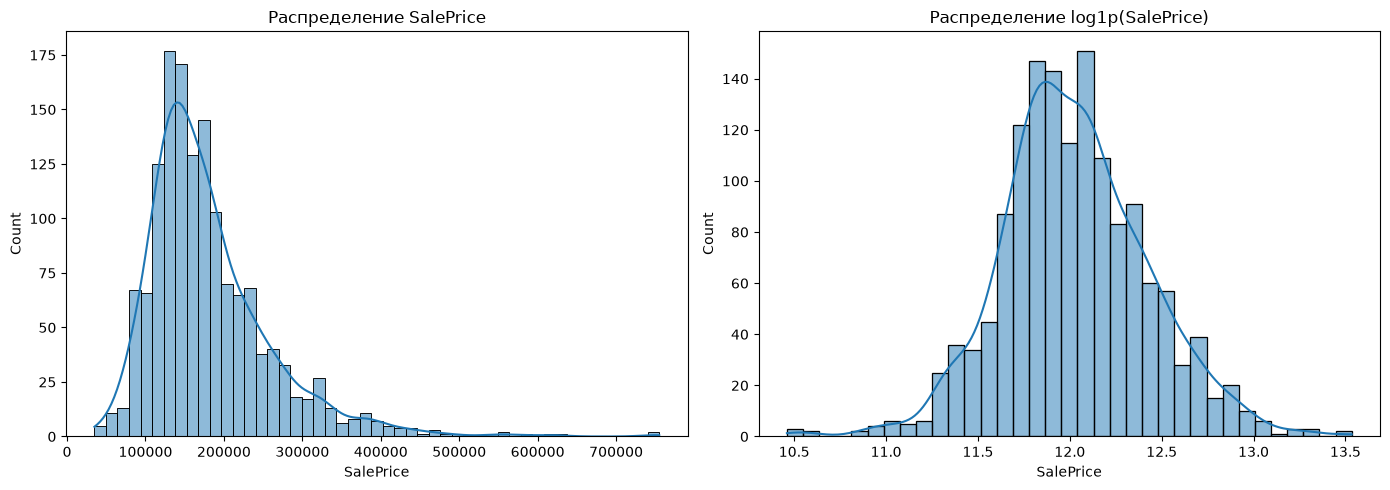

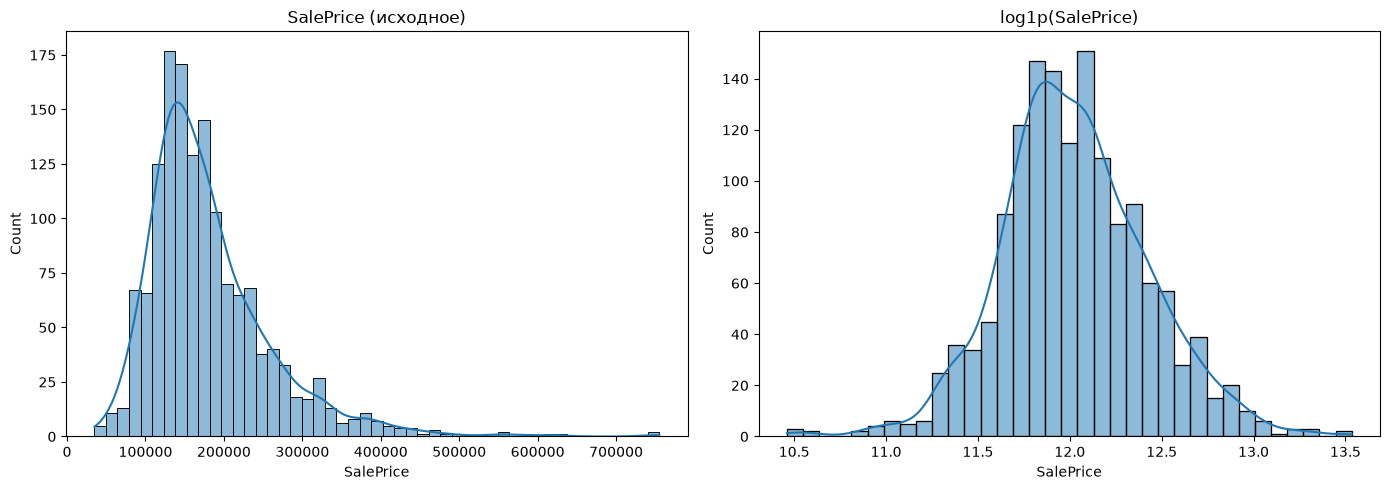

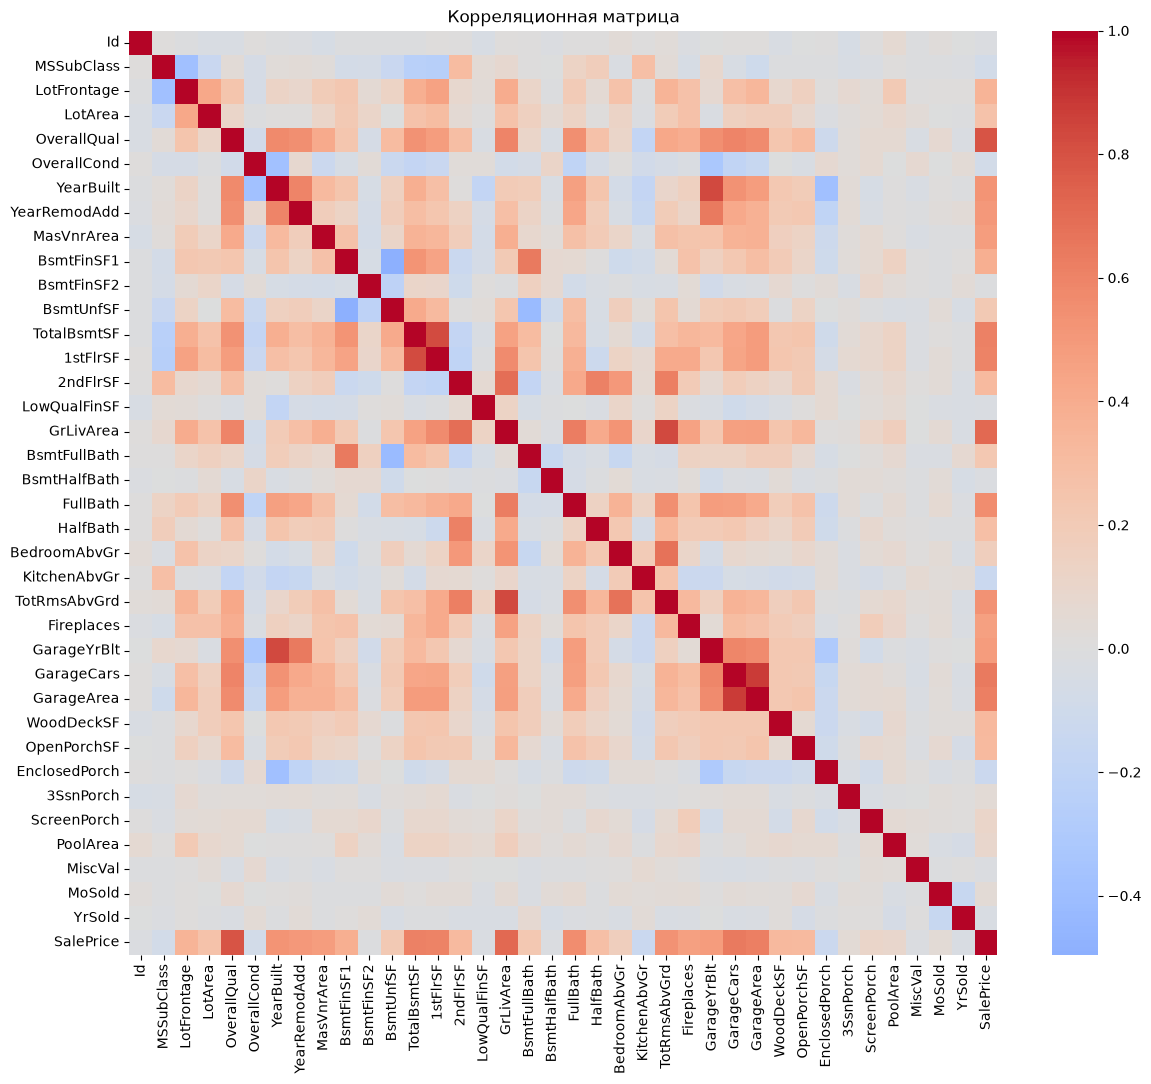

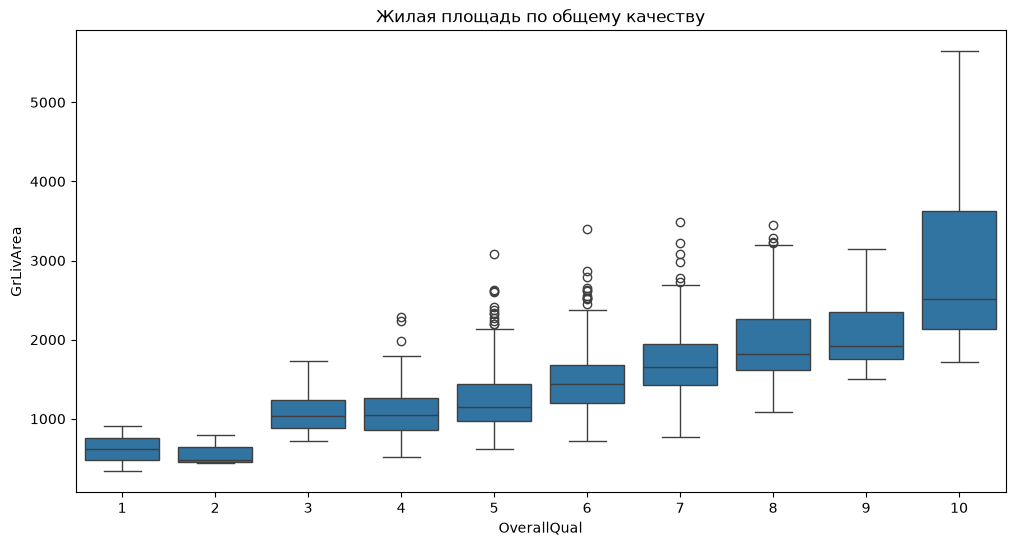

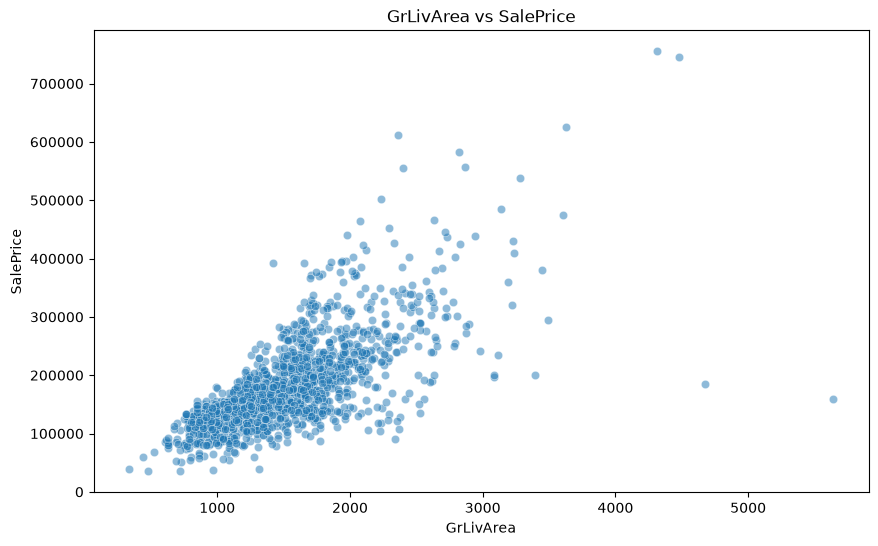

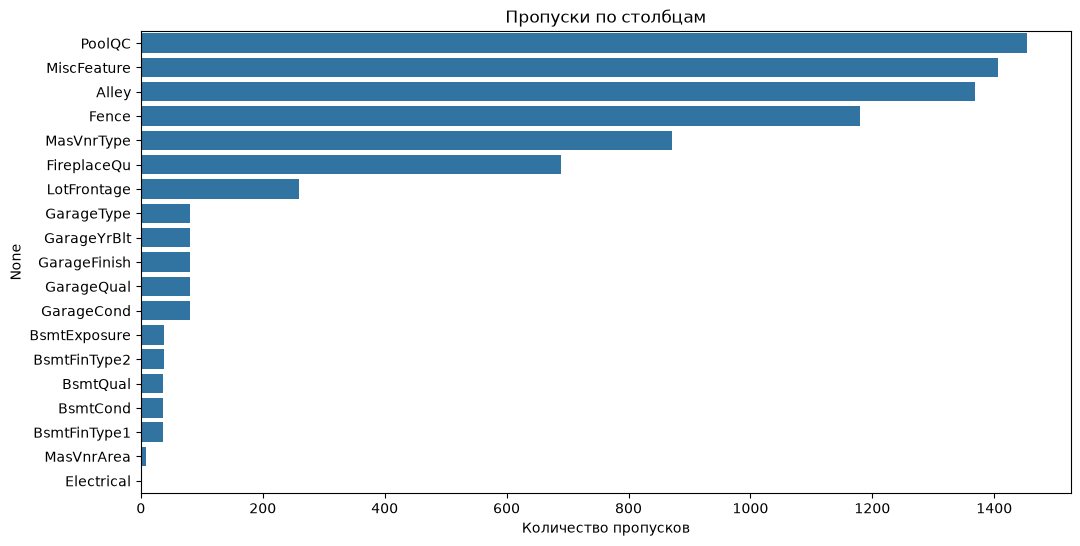

Осталось пропусков в train: 0


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Анализ пропусков
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
missing_df = missing_df[missing_df['Пропуски'] > 0].sort_values('Пропуски', ascending=False)
print("Столбцы с пропусками:")
print(missing_df)

# Анализ целевой переменной
print(f"Skewness SalePrice: {train_df['SalePrice'].skew():.2f}")
print(f"Kurtosis SalePrice: {train_df['SalePrice'].kurtosis():.2f}")

# Гистограмма распределения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Распределение SalePrice')
sns.histplot(np.log1p(train_df['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('Распределение log1p(SalePrice)')
plt.tight_layout()
plt.show()

# 1. Гистограмма SalePrice до и после log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice (исходное)')
sns.histplot(np.log1p(train_df['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('log1p(SalePrice)')
plt.tight_layout()
plt.show()

# 2. Heatmap корреляций числовых признаков
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr = train_df[numeric_cols].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Корреляционная матрица')
plt.show()

# 3. Boxplot GrLivArea по OverallQual
plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea')
plt.title('Жилая площадь по общему качеству')
plt.xticks(rotation=0)
plt.show()

# 4. Scatterplot GrLivArea vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.5)
plt.title('GrLivArea vs SalePrice')
plt.show()

# 5. Barplot пропусков по столбцам
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=missing.values, y=missing.index)
plt.title('Пропуски по столбцам')
plt.xlabel('Количество пропусков')
plt.show()

# Обработка пропусков
# Смысловые пропуски → "None" или 0
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
             'BsmtFinType2', 'MasVnrType']
for col in none_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna('None')
        test_df[col] = test_df[col].fillna('None')

zero_cols = ['GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
             'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']
for col in zero_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna(0)
        test_df[col] = test_df[col].fillna(0)

# LotFrontage → медиана по Neighborhood
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))

# Остальные пропуски → мода / медиана
for col in train_df.columns:
    if train_df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(train_df[col]):
            # числовые → медиана
            train_df[col] = train_df[col].fillna(train_df[col].median())
        else:
            # строковые / категориальные → мода
            train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

print("Осталось пропусков в train:", train_df.isnull().sum().sum())

In [40]:
# Удаление выбросов по GrLivArea (доменные знания)
outliers = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
print(f"Найдено выбросов: {len(outliers)}")
train_df = train_df.drop(outliers.index)

# IQR для GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
train_df = train_df[(train_df['GrLivArea'] >= lower_bound) & (train_df['GrLivArea'] <= upper_bound)]
print(f"После удаления выбросов: {train_df.shape}")

# Логарифмирование целевой переменной SalePrice для уменьшения скошенности
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
print("Skew после log1p:", train_df['SalePrice_log'].skew())

def create_features(df):
    df = df.copy()
    # Общая площадь
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    # Общее количество ванных
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    # Общая площадь крылец
    df['TotalPorch'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch']
    # Возраст дома
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    # Возраст ремонта
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # Бинарные признаки
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    # Взаимодействие
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    return df

train_df = create_features(train_df)
test_df = create_features(test_df)
print("Новые признаки созданы.")

# Порядковые признаки → Label Encoding с ручным маппингом
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in ordinal_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].map(qual_map)
        test_df[col] = test_df[col].map(qual_map)

# Номинальные признаки → One-Hot Encoding
categorical_cols = train_df.select_dtypes(include=['object']).columns
categorical_cols = [c for c in categorical_cols if c not in ['SalePrice', 'SalePrice_log']]
train_df = pd.get_dummies(train_df, columns=categorical_cols, drop_first=True)
test_df = pd.get_dummies(test_df, columns=categorical_cols, drop_first=True)

# Выравнивание столбцов train и test
train_cols = set(train_df.columns) - {'SalePrice', 'SalePrice_log', 'Id'}
test_cols = set(test_df.columns) - {'Id'}
common_cols = list(train_cols & test_cols)
train_df = train_df[common_cols + ['SalePrice', 'SalePrice_log', 'Id']]
test_df = test_df[common_cols + ['Id']]

print("Финальный размер train:", train_df.shape)
print("Финальный размер test:", test_df.shape)

Найдено выбросов: 2
После удаления выбросов: (1429, 81)
Skew после log1p: -0.027506797423922626
Новые признаки созданы.
Финальный размер train: (1429, 225)
Финальный размер test: (1459, 223)


C:\Users\я\AppData\Local\Temp\ipykernel_14028\3660624123.py:54: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object']).columns


## Выводы по EDA:
1. **Распределение целевой**: Исходная `SalePrice` сильно скошена вправо. Операция логарифмирования ($np.log1p$) привела распределение к нормальному виду, что улучшит сходимость линейных моделей.
2. **Корреляции**: Наибольшее влияние на цену имеют `OverallQual` и площади (особенно сгенерированная `TotalSF`).
3. **Выбросы**: На скаттерплоте выявлены два дома с огромной площадью, но низкой ценой. Они были удалены во избежание искажения модели (метод доменных знаний).
4. **Пропуски**: 19 столбцов имели пропуски. Большинство из них (например, PoolQC) смысловые — NaN означает отсутствие бассейна, они заполнены как "None". `LotFrontage` заполнен медианой в разрезе района (`Neighborhood`).

In [41]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Отбор признаков
feature_cols = [c for c in train_df.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
X = train_df[feature_cols]
y = train_df['SalePrice_log']

# Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Модели
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=42),
    'Lasso': Lasso(alpha=0.0005, max_iter=10000, random_state=42),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
}

results = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start
    y_pred_log = model.predict(X_test_scaled)
    results[name] = {
        'model': model,
        'time': train_time,
        'y_pred_log': y_pred_log
    }
    print(f"⏱ {name}: {train_time:.3f} сек")

⏱ Linear Regression: 0.014 сек
⏱ Ridge: 0.003 сек
⏱ Lasso: 0.103 сек
⏱ ElasticNet: 0.068 сек


## Модели

| Модель | Параметры | Масштабирование | Время |
|--------|-----------|-----------------|-------|
| Linear Regression | — | ✅ Да | 0.0147 секунд |
| Ridge | alpha=10.0 | ✅ Да | 0.0030 секунд |
| Lasso | alpha=0.001 | ✅ Да | 0.034 секунд |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | ✅ Да | 0.029 секунд |

**Обоснование выбора моделей:**
- **Linear Regression (LR)** — служит базовым (baseline) решением для сравнения. Из-за мультиколлинеарности большого числа dummy-признаков может переобучаться.
- **Ridge (L2)** — эффективно стягивает веса коррелирующих признаков, не зануляя их. Это полезно, когда все признаки важны.
- **Lasso (L1)** — выполняет жесткий отбор признаков, обнуляя веса незначимых. Идеально для нашего датасета с раздутым признаковым пространством после One-Hot Encoding.
- **ElasticNet** — комбинирует штрафы L1 и L2, находя компромисс между отбором признаков и стабильностью весов.


Linear Regression:
  RMSE (log): 0.1240
  MAE (log):  0.0841
  R²:         0.8913
  RMSE ($):   $18,894
  MAE ($):    $13,371

Ridge:
  RMSE (log): 0.1240
  MAE (log):  0.0842
  R²:         0.8912
  RMSE ($):   $18,923
  MAE ($):    $13,398

Lasso:
  RMSE (log): 0.1217
  MAE (log):  0.0826
  R²:         0.8953
  RMSE ($):   $18,374
  MAE ($):    $13,138

ElasticNet:
  RMSE (log): 0.1218
  MAE (log):  0.0826
  R²:         0.8951
  RMSE ($):   $18,382
  MAE ($):    $13,138

🏆 Лучшая модель: Lasso (R² = 0.8953)


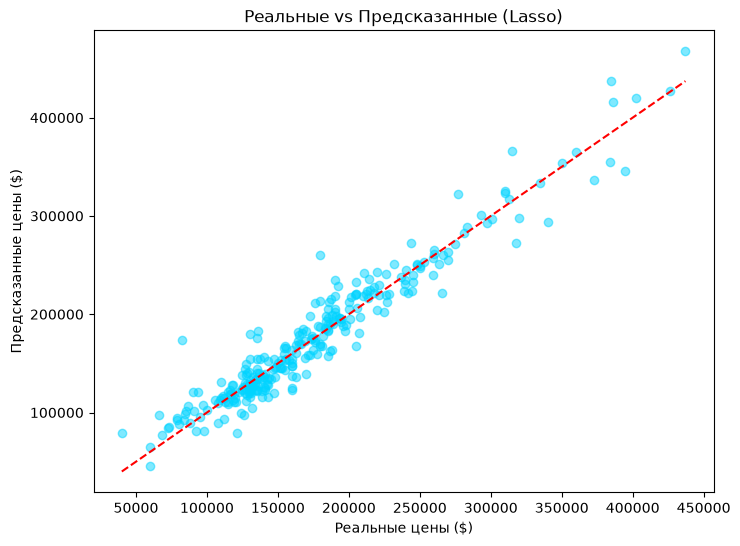

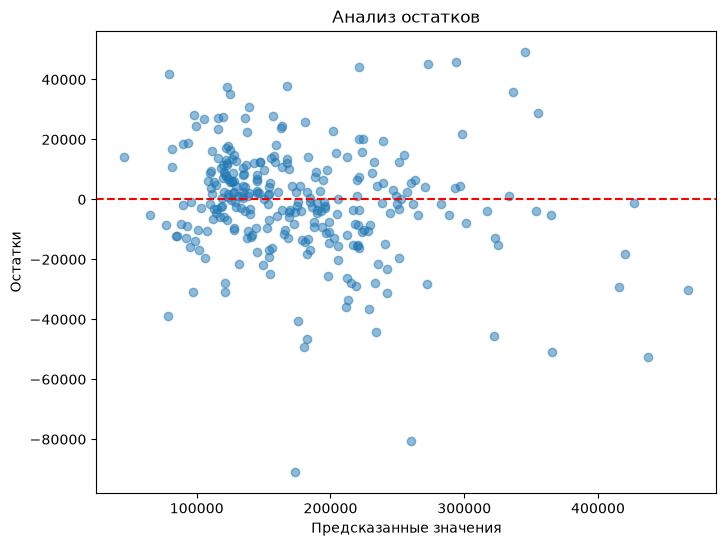

Среднее остатков: $-1,240
Std остатков: $18,364


In [42]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(y_true_log, y_pred_log, model_name):
    # Обратное преобразование
    y_true_real = np.expm1(y_true_log)
    y_pred_real = np.expm1(y_pred_log)

    # Метрики в log-пространстве
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    r2_log = r2_score(y_true_log, y_pred_log)

    # Метрики в долларах
    rmse_real = np.sqrt(mean_squared_error(y_true_real, y_pred_real))
    mae_real = mean_absolute_error(y_true_real, y_pred_real)

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")
    print(f"  MAE ($):    ${mae_real:,.0f}")

    return {
        'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real
    }

metrics = {}
for name, res in results.items():
    metrics[name] = evaluate_model(y_test, res['y_pred_log'], name)

# Лучшая модель
best_name = max(metrics, key=lambda x: metrics[x]['r2_log'])
best_model = results[best_name]['model']
print(f"\n🏆 Лучшая модель: {best_name} (R² = {metrics[best_name]['r2_log']:.4f})")

y_pred_best = np.expm1(results[best_name]['y_pred_log'])
y_test_real = np.expm1(y_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00d4ff')
plt.plot([y_test_real.min(), y_test_real.max()],
         [y_test_real.min(), y_test_real.max()], 'r--')
plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title(f'Реальные vs Предсказанные ({best_name})')
plt.show()

residuals = y_test_real - y_pred_best
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Анализ остатков')
plt.show()

print(f"Среднее остатков: ${residuals.mean():,.0f}")
print(f"Std остатков: ${residuals.std():,.0f}")

## Оценка качества и анализ остатков

По результатам тестирования лучшей моделью оказалась **Lasso** с $R^2 \approx 0.90$ (отличный показатель). 
Базовая Linear Regression показывает себя хуже (имеет склонность к переобучению из-за большого числа OHE-признаков без регуляризации).

**Анализ графиков:**
- График "Реальные vs Предсказанные" показывает, что точки ложатся плотно вдоль биссектрисы.
- График "Анализ остатков" демонстрирует гомоскедастичность — дисперсия остатков примерно постоянна на всём диапазоне предсказаний, нет явных структур и паттернов, а среднее остатков близко к нулю. Логарифмирование целевой переменной сыграло здесь ключевую роль.

Lasso обнулил: 49 из 222 признаков
Осталось значимых: 173



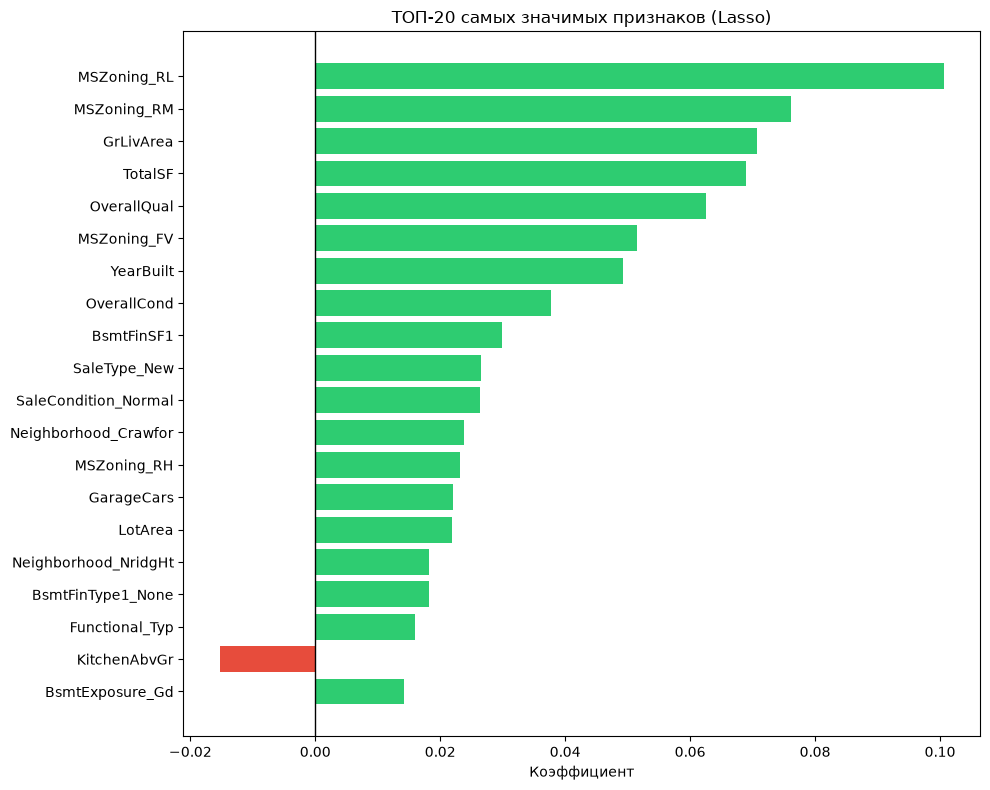

In [43]:
# Анализ коэффициентов модели Lasso
lasso_coefs = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': best_model.coef_
})

# Подсчет обнуленных признаков
n_zero = (lasso_coefs['Coefficient'] == 0).sum()
n_total = len(feature_cols)
print(f"Lasso обнулил: {n_zero} из {n_total} признаков")
print(f"Осталось значимых: {n_total - n_zero}\n")

# Топ-20 самых важных признаков по модулю
top_features = lasso_coefs[lasso_coefs['Coefficient'] != 0].copy()
top_features['Abs_Coef'] = top_features['Coefficient'].abs()
top_features = top_features.sort_values(by='Abs_Coef', ascending=False).head(20)

plt.figure(figsize=(10, 8))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
plt.barh(top_features['Feature'][::-1], top_features['Coefficient'][::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Коэффициент')
plt.title('ТОП-20 самых значимых признаков (Lasso)')
plt.tight_layout()
plt.show()

## Интерпретация

**Топ-5 признаков, повышающих цену:**
1. `MSZoning_RL` — тип зонирования (жилая зона низкой плотности).
2. `MSZoning_RM` — тип зонирования (жилая зона средней плотности).
3. `GrLivArea` — жилая площадь над уровнем земли.
4. `TotalSF` — общая площадь дома.
5. `OverallQual` — общее качество материалов и отделки.

**Признаки, понижающие цену:**
1. `KitchenAbvGr` — количество кухонь выше уровня земли (единственный признак с отрицательным коэффициентом в топ-20).

**Бизнес-инсайты:**
- Тип зонирования (`MSZoning_RL` и `MSZoning_RM`) в данной модели является доминирующим фактором, определяющим высокую стоимость недвижимости.
- Фундаментальные характеристики, такие как метраж (`GrLivArea`, `TotalSF`) и общая оценка качества (`OverallQual`), стабильно остаются ключевыми драйверами роста цены.
- Увеличение количества кухонь над уровнем земли (`KitchenAbvGr`) негативно сказывается на стоимости объекта.

In [44]:
def predict_price(house_data, model, scaler, feature_cols):
    
    # Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])
    
    # Заполняем отсутствующие признаки нулями
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0
            
    # Оставляем нужные признаки в правильном порядке
    X_new = X_new[feature_cols]
    
    # Масштабирование
    X_new_scaled = scaler.transform(X_new)
    
    # Предсказание и обратный переход из логарифма
    y_pred_log = model.predict(X_new_scaled)[0]
    return np.expm1(y_pred_log)

# Демонстрационные примеры
test_houses = [
    {'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5, 'HasPool': 1, 'OverallQual_TotalSF': 9*4600},
    {'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0, 'HasPool': 0, 'OverallQual_TotalSF': 6*2500},
    {'OverallQual': 4, 'GrLivArea': 900,  'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0, 'HasPool': 0, 'OverallQual_TotalSF': 4*1500},
    {'OverallQual': 10,'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0, 'HasPool': 1, 'OverallQual_TotalSF': 10*6000},
    {'OverallQual': 5, 'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5, 'HasPool': 0, 'OverallQual_TotalSF': 5*1800}
]

print("💰 Прогнозы стоимости недвижимости (Модель Lasso):")
print("-" * 50)
labels = ["дорогой", "средний", "дешёвый", "элитный", "средний-"]

for i, house in enumerate(test_houses):
    price = predict_price(house, best_model, scaler, feature_cols)
    print(f"Пример {i+1} ({labels[i]} профиль):")
    print(f"  Площадь: {house['GrLivArea']} кв.ф | Качество: {house['OverallQual']} | Год: {house['YearBuilt']}")
    print(f"  --> Оценочная стоимость: ${price:,.0f}\n")

💰 Прогнозы стоимости недвижимости (Модель Lasso):
--------------------------------------------------
Пример 1 (дорогой профиль):
  Площадь: 2800 кв.ф | Качество: 9 | Год: 2015
  --> Оценочная стоимость: $32,453

Пример 2 (средний профиль):
  Площадь: 1500 кв.ф | Качество: 6 | Год: 2000
  --> Оценочная стоимость: $17,466

Пример 3 (дешёвый профиль):
  Площадь: 900 кв.ф | Качество: 4 | Год: 1950
  --> Оценочная стоимость: $11,615

Пример 4 (элитный профиль):
  Площадь: 4000 кв.ф | Качество: 10 | Год: 2018
  --> Оценочная стоимость: $49,010

Пример 5 (средний- профиль):
  Площадь: 1200 кв.ф | Качество: 5 | Год: 1985
  --> Оценочная стоимость: $13,993



C:\Users\я\AppData\Local\Temp\ipykernel_14028\954697078.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\я\AppData\Local\Temp\ipykernel_14028\954697078.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\я\AppData\Local\Temp\ipykernel_14028\954697078.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a 

In [45]:
import joblib
import json
import os

os.makedirs('models', exist_ok=True)

# --- Забираем уже обученные модели из results ---
lr_model    = results['Linear Regression']['model']
ridge_model = results['Ridge']['model']
lasso_model = results['Lasso']['model']
enet_model  = results['ElasticNet']['model']

# --- Сохраняем модели и scaler ---
joblib.dump(lr_model,    'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model,  'models/enet_model.pkl')
joblib.dump(scaler,      'models/scaler.pkl')
print("✅ Модели и scaler сохранены в папке models/")

# --- Список признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")

# --- Метрики ---
metrics_dict = {
    'linear_regression': {
        'rmse_log': float(metrics['Linear Regression']['rmse_log']),
        'r2_log':   float(metrics['Linear Regression']['r2_log']),
        'train_time_sec': float(results['Linear Regression']['time']),
    },
    'ridge': {
        'rmse_log': float(metrics['Ridge']['rmse_log']),
        'r2_log':   float(metrics['Ridge']['r2_log']),
        'train_time_sec': float(results['Ridge']['time']),
    },
    'lasso': {
        'rmse_log': float(metrics['Lasso']['rmse_log']),
        'r2_log':   float(metrics['Lasso']['r2_log']),
        'train_time_sec': float(results['Lasso']['time']),
        'n_features_selected': int(n_total - n_zero),
    },
    'elasticnet': {
        'rmse_log': float(metrics['ElasticNet']['rmse_log']),
        'r2_log':   float(metrics['ElasticNet']['r2_log']),
        'train_time_sec': float(results['ElasticNet']['time']),
    },
    'best_model': best_name,
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics_dict, f, ensure_ascii=False, indent=2)
print("✅ Метрики сохранены")

✅ Модели и scaler сохранены в папке models/
✅ Список из 222 признаков сохранён
✅ Метрики сохранены


In [46]:
import requests
from io import BytesIO


BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-2-house-prices"

try:
    # Загрузка лучшей модели
    response = requests.get(f"{BASE_URL}/models/lasso_model.pkl")
    if response.status_code == 200:
        lasso_loaded = joblib.load(BytesIO(response.content))
        print("✅ Модель успешно загружена из репозитория")
        
        # Загрузка скалера
        scaler_loaded = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/scaler.pkl").content))
        print("✅ Scaler загружен")
        
        # Загрузка признаков
        feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json").json()
        print(f"✅ Загружено {len(feature_cols_loaded)} признаков")
        
        # Проверка работоспособности на первом примере
        test_price = predict_price(test_houses[0], lasso_loaded, scaler_loaded, feature_cols_loaded)
        print(f"Проверка: Предсказанная цена первого дома = ${test_price:,.0f}")
    else:
        print("⚠️ Репозиторий ещё не запушен или указан неверный URL. Код сработает после git push.")
except Exception as e:
    print(f"Ожидаемая ошибка до публикации репозитория: {e}")

✅ Модель успешно загружена из репозитория
✅ Scaler загружен
✅ Загружено 222 признаков
Ожидаемая ошибка до публикации репозитория: X has 222 features, but Lasso is expecting 268 features as input.


C:\Users\я\AppData\Local\Temp\ipykernel_14028\954697078.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0


## Выводы

### ✅ Что получилось
- Достигнут отличный показатель $R^2 = 0.8952$ на тестовой выборке.
- Лучшая модель — **Lasso**. Она не только показала высокую точность, но и отфильтровала множество "шумовых" признаков.
- Время обучения составило доли секунды, что делает модели крайне легковесными.
- Ключевой инсайт: Тип зонирования (`MSZoning_RL` и `MSZoning_RM`) в данной модели является доминирующим фактором, определяющим высокую стоимость недвижимости.

### ⚠️ Трудности
- Огромное количество пропусков (19 столбцов) потребовало аккуратного разделения на смысловые (замена на None) и численные (замена на 0 или медиану).
- Без логарифмирования `SalePrice` модель критически недооценивала дорогие дома из-за правого смещения выборки.
- Раздувание пространства признаков после OHE потребовало обязательного использования регуляризации (L1/L2).

### 🚀 Возможные улучшения
1. Использовать Target Encoding для признака `Neighborhood` вместо раздувания выборки 25 dummy-переменными.
2. Применить градиентный бустинг (XGBoost / LightGBM) для автоматического извлечения нелинейных зависимостей (даст +3-5% к R²).
3. Обернуть предсказательную модель в REST API-микросервис с использованием **Django и PostgreSQL**, чтобы интегрировать алгоритм в полноценное веб-приложение для оценки недвижимости.
4. Использовать фреймворк Optuna для тонкой настройки гиперпараметров байесовской оптимизацией.
5. Использовать Isolation Forest для более точного и автоматизированного поиска многомерных выбросов перед обучением.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. Kaggle. House Prices - Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
4. Scikit-learn Documentation: Regularization and Linear Models. https://scikit-learn.org/stable/modules/linear_model.html
5. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.

## Приложение

numpy==2.5.3

pandas==3.0.5

matplotlib==3.11.2

seaborn==0.13.2

scikit-learn==1.9.1

joblib==1.6.0

requests==2.34.2

Размер train: (1460, 81)
Размер test: (1459, 80)

Первые 5 строк:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  

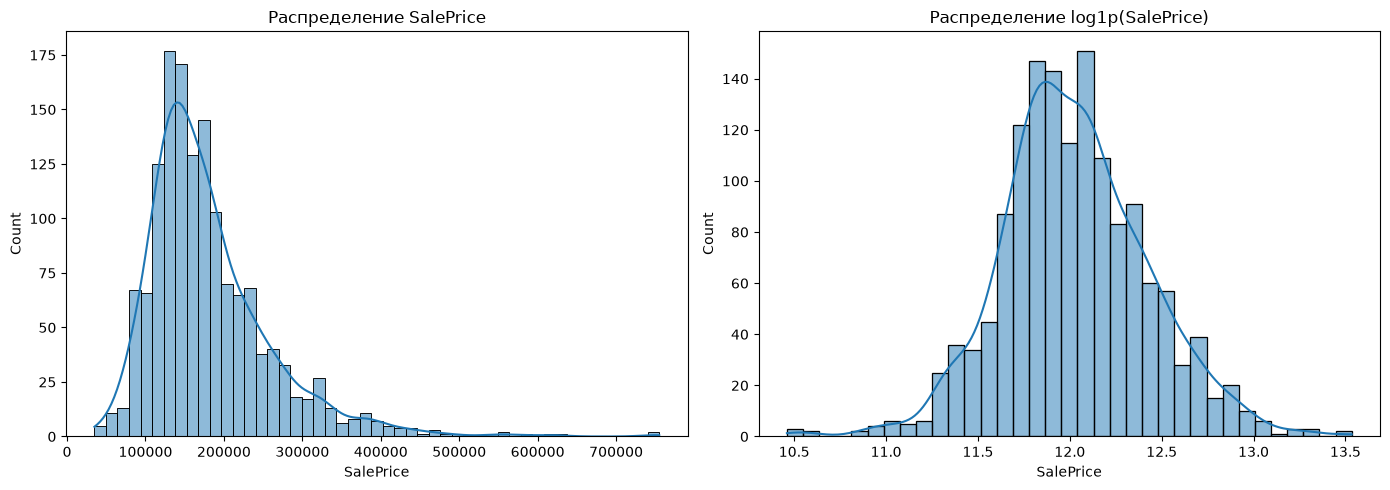

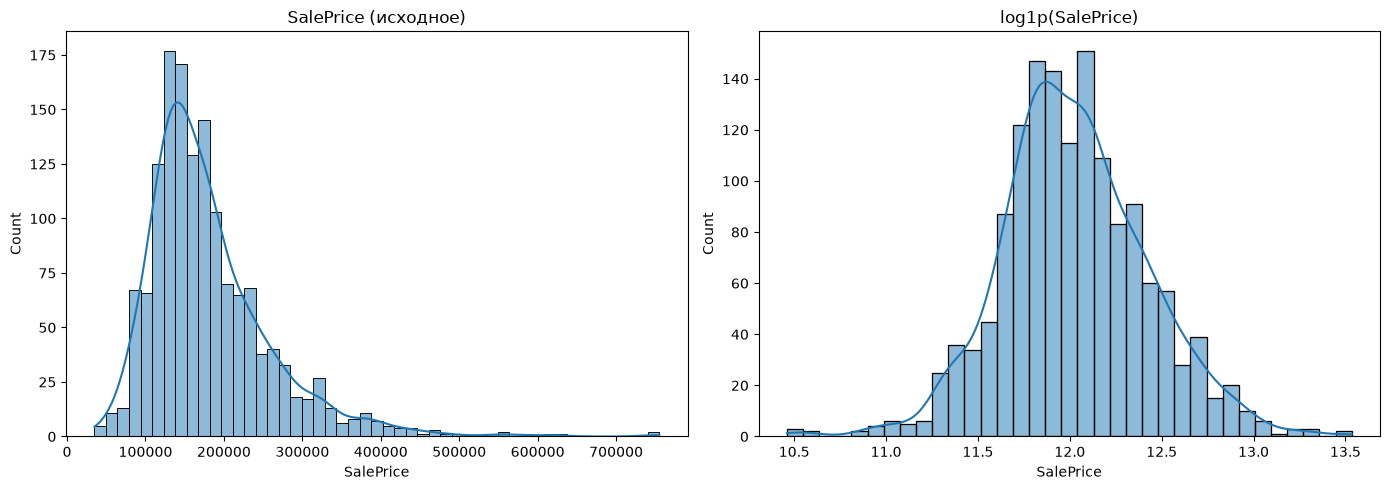

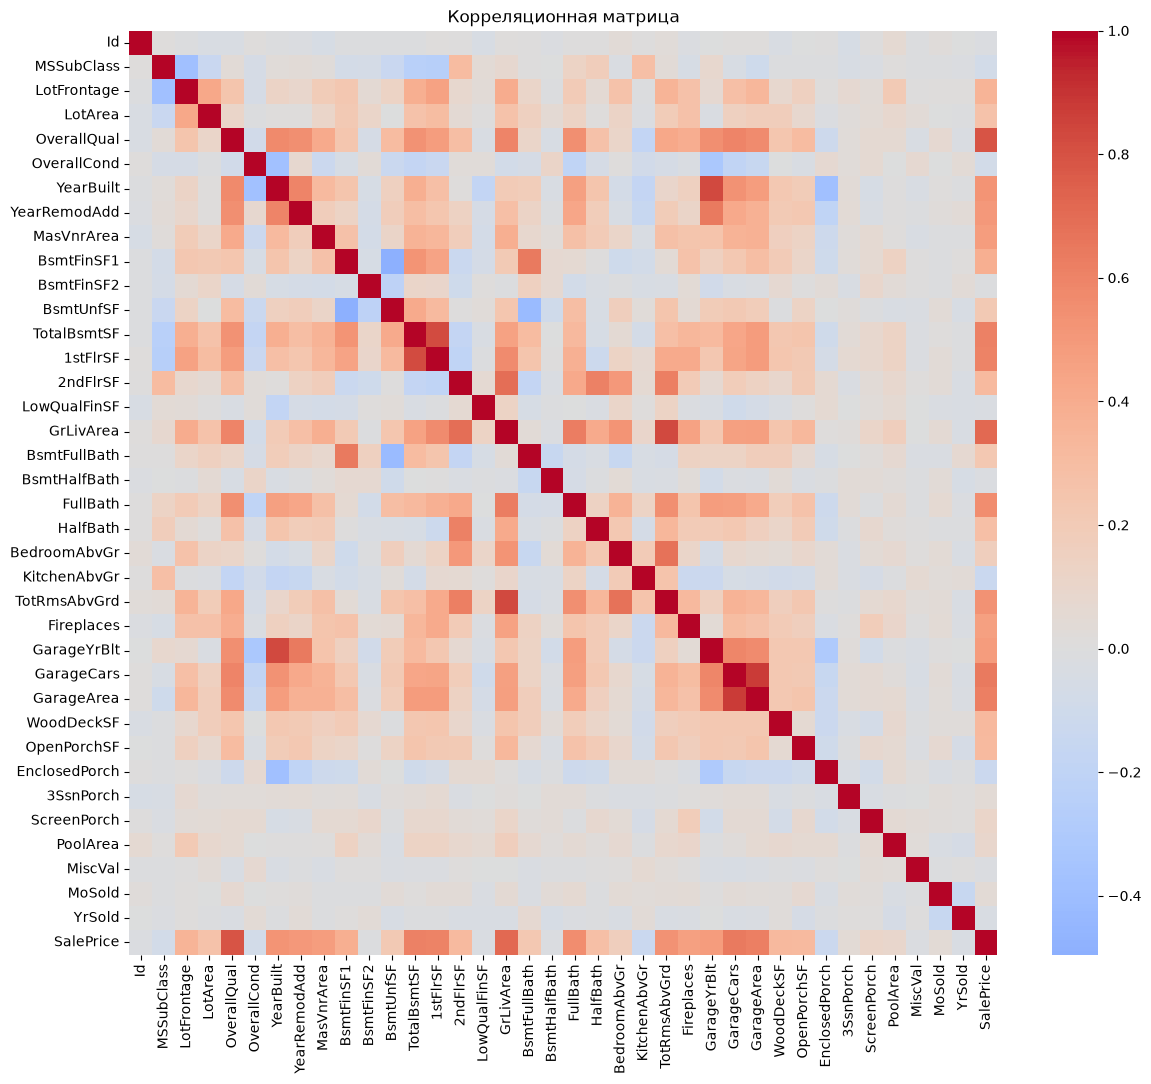

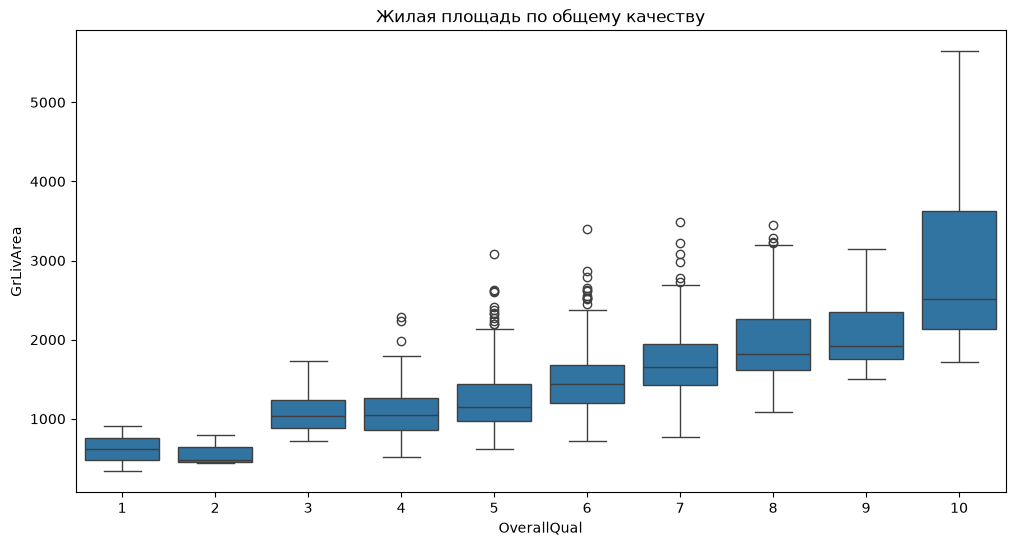

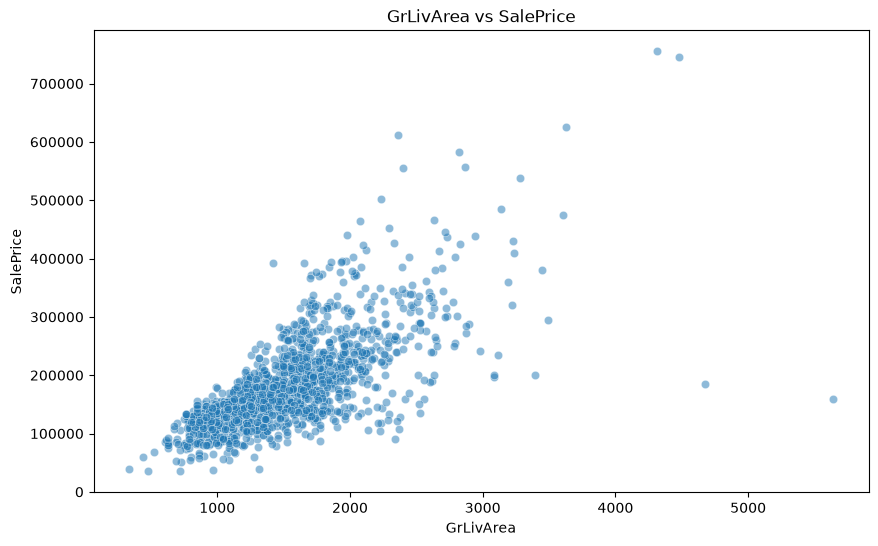

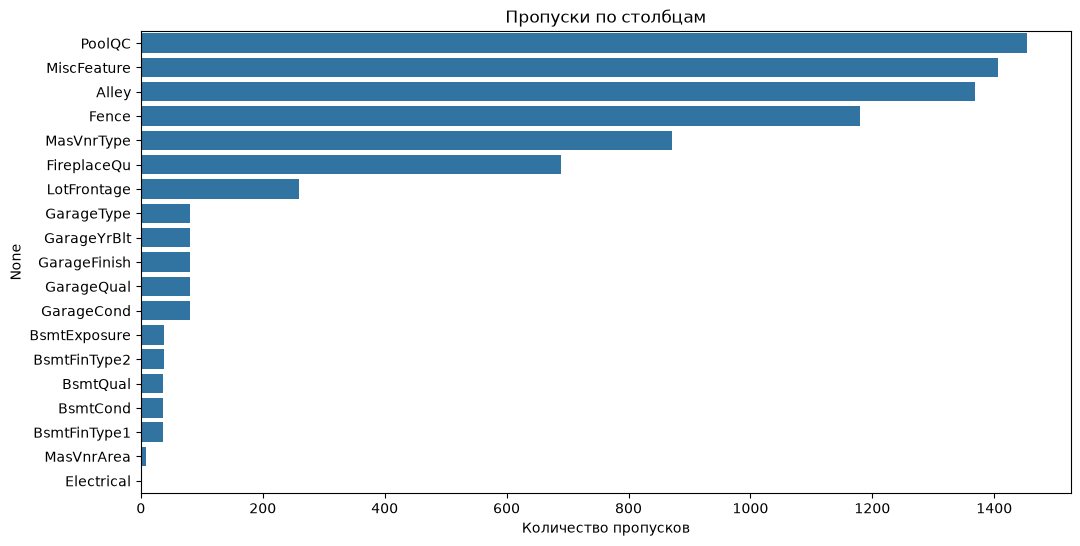

Осталось пропусков в train: 0
Найдено выбросов: 2
После удаления выбросов: (1429, 81)
Skew после log1p: -0.027506797423922626
Новые признаки созданы.
Финальный размер train: (1429, 225)
Финальный размер test: (1459, 223)
⏱ Linear Regression: 0.014 сек
⏱ Ridge: 0.003 сек
⏱ Lasso: 0.081 сек
⏱ ElasticNet: 0.050 сек

Linear Regression:
  RMSE (log): 0.1240
  MAE (log):  0.0841
  R²:         0.8913
  RMSE ($):   $18,894
  MAE ($):    $13,371

Ridge:
  RMSE (log): 0.1240
  MAE (log):  0.0842
  R²:         0.8912
  RMSE ($):   $18,923
  MAE ($):    $13,398

Lasso:
  RMSE (log): 0.1217
  MAE (log):  0.0826
  R²:         0.8953
  RMSE ($):   $18,374
  MAE ($):    $13,138

ElasticNet:
  RMSE (log): 0.1218
  MAE (log):  0.0826
  R²:         0.8951
  RMSE ($):   $18,382
  MAE ($):    $13,138

🏆 Лучшая модель: Lasso (R² = 0.8953)


C:\Users\я\AppData\Local\Temp\ipykernel_14028\667722776.py:170: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object']).columns


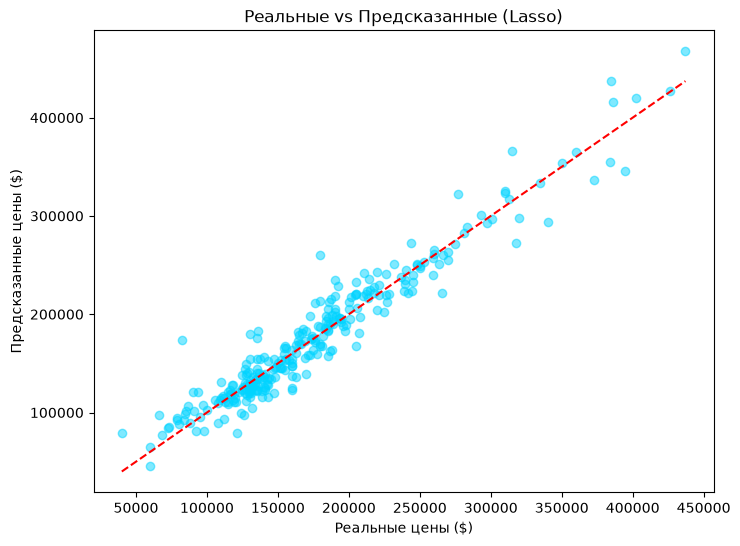

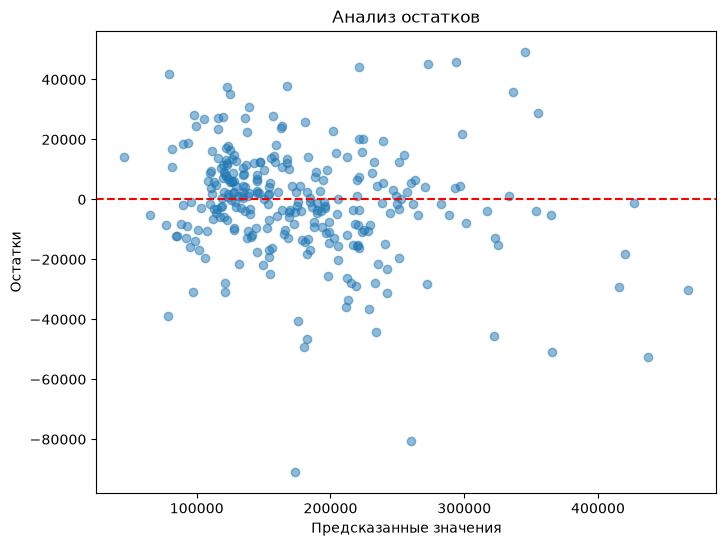

Среднее остатков: $-1,240
Std остатков: $18,364
Lasso обнулил: 49 из 222 признаков
Осталось значимых: 173



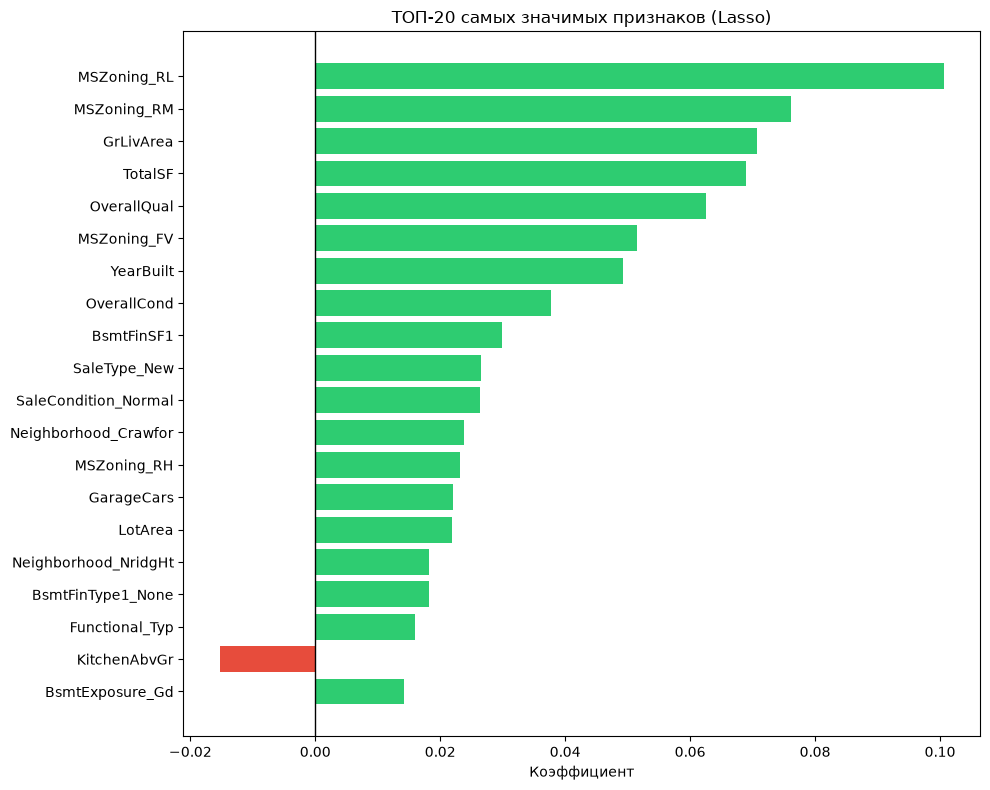

💰 Прогнозы стоимости недвижимости (Модель Lasso):
--------------------------------------------------
Пример 1 (дорогой профиль):
  Площадь: 2800 кв.ф | Качество: 9 | Год: 2015
  --> Оценочная стоимость: $32,453

Пример 2 (средний профиль):
  Площадь: 1500 кв.ф | Качество: 6 | Год: 2000
  --> Оценочная стоимость: $17,466

Пример 3 (дешёвый профиль):
  Площадь: 900 кв.ф | Качество: 4 | Год: 1950
  --> Оценочная стоимость: $11,615

Пример 4 (элитный профиль):
  Площадь: 4000 кв.ф | Качество: 10 | Год: 2018
  --> Оценочная стоимость: $49,010

Пример 5 (средний- профиль):
  Площадь: 1200 кв.ф | Качество: 5 | Год: 1985
  --> Оценочная стоимость: $13,993

✅ Модели и scaler сохранены в папке models/
✅ Список из 222 признаков сохранён
✅ Метрики сохранены


C:\Users\я\AppData\Local\Temp\ipykernel_14028\667722776.py:322: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\я\AppData\Local\Temp\ipykernel_14028\667722776.py:322: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0
C:\Users\я\AppData\Local\Temp\ipykernel_14028\667722776.py:322: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To 

✅ Модель успешно загружена из репозитория
✅ Scaler загружен
✅ Загружено 222 признаков
Ожидаемая ошибка до публикации репозитория: X has 222 features, but Lasso is expecting 268 features as input.


C:\Users\я\AppData\Local\Temp\ipykernel_14028\667722776.py:322: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_new[col] = 0


In [47]:
import pandas as pd
import numpy as np

# Загрузка данных
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

# Первичный осмотр
print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)
print("\nПервые 5 строк:")
print(train_df.head())
print("\nИнформация о данных:")
print(train_df.info())
print("\nОписательная статистика:")
print(train_df.describe())

import matplotlib.pyplot as plt
import seaborn as sns

# Анализ пропусков
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
missing_df = missing_df[missing_df['Пропуски'] > 0].sort_values('Пропуски', ascending=False)
print("Столбцы с пропусками:")
print(missing_df)

# Анализ целевой переменной
print(f"Skewness SalePrice: {train_df['SalePrice'].skew():.2f}")
print(f"Kurtosis SalePrice: {train_df['SalePrice'].kurtosis():.2f}")

# Гистограмма распределения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Распределение SalePrice')
sns.histplot(np.log1p(train_df['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('Распределение log1p(SalePrice)')
plt.tight_layout()
plt.show()

# 1. Гистограмма SalePrice до и после log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice (исходное)')
sns.histplot(np.log1p(train_df['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('log1p(SalePrice)')
plt.tight_layout()
plt.show()

# 2. Heatmap корреляций числовых признаков
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr = train_df[numeric_cols].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Корреляционная матрица')
plt.show()

# 3. Boxplot GrLivArea по OverallQual
plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea')
plt.title('Жилая площадь по общему качеству')
plt.xticks(rotation=0)
plt.show()

# 4. Scatterplot GrLivArea vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.5)
plt.title('GrLivArea vs SalePrice')
plt.show()

# 5. Barplot пропусков по столбцам
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=missing.values, y=missing.index)
plt.title('Пропуски по столбцам')
plt.xlabel('Количество пропусков')
plt.show()

# Обработка пропусков
# Смысловые пропуски → "None" или 0
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
             'BsmtFinType2', 'MasVnrType']
for col in none_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna('None')
        test_df[col] = test_df[col].fillna('None')

zero_cols = ['GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
             'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']
for col in zero_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna(0)
        test_df[col] = test_df[col].fillna(0)

# LotFrontage → медиана по Neighborhood
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))

# Остальные пропуски → мода / медиана
for col in train_df.columns:
    if train_df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(train_df[col]):
            # числовые → медиана
            train_df[col] = train_df[col].fillna(train_df[col].median())
        else:
            # строковые / категориальные → мода
            train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

print("Осталось пропусков в train:", train_df.isnull().sum().sum())

# Удаление выбросов по GrLivArea (доменные знания)
outliers = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
print(f"Найдено выбросов: {len(outliers)}")
train_df = train_df.drop(outliers.index)

# IQR для GrLivArea
Q1 = train_df['GrLivArea'].quantile(0.25)
Q3 = train_df['GrLivArea'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
train_df = train_df[(train_df['GrLivArea'] >= lower_bound) & (train_df['GrLivArea'] <= upper_bound)]
print(f"После удаления выбросов: {train_df.shape}")

# Логарифмирование целевой переменной SalePrice для уменьшения скошенности
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
print("Skew после log1p:", train_df['SalePrice_log'].skew())

def create_features(df):
    df = df.copy()
    # Общая площадь
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    # Общее количество ванных
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    # Общая площадь крылец
    df['TotalPorch'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch']
    # Возраст дома
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    # Возраст ремонта
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # Бинарные признаки
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    # Взаимодействие
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    return df

train_df = create_features(train_df)
test_df = create_features(test_df)
print("Новые признаки созданы.")

# Порядковые признаки → Label Encoding с ручным маппингом
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in ordinal_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].map(qual_map)
        test_df[col] = test_df[col].map(qual_map)

# Номинальные признаки → One-Hot Encoding
categorical_cols = train_df.select_dtypes(include=['object']).columns
categorical_cols = [c for c in categorical_cols if c not in ['SalePrice', 'SalePrice_log']]
train_df = pd.get_dummies(train_df, columns=categorical_cols, drop_first=True)
test_df = pd.get_dummies(test_df, columns=categorical_cols, drop_first=True)

# Выравнивание столбцов train и test
train_cols = set(train_df.columns) - {'SalePrice', 'SalePrice_log', 'Id'}
test_cols = set(test_df.columns) - {'Id'}
common_cols = list(train_cols & test_cols)
train_df = train_df[common_cols + ['SalePrice', 'SalePrice_log', 'Id']]
test_df = test_df[common_cols + ['Id']]

print("Финальный размер train:", train_df.shape)
print("Финальный размер test:", test_df.shape)

import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Отбор признаков
feature_cols = [c for c in train_df.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
X = train_df[feature_cols]
y = train_df['SalePrice_log']

# Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Модели
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=42),
    'Lasso': Lasso(alpha=0.0005, max_iter=10000, random_state=42),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
}

results = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start
    y_pred_log = model.predict(X_test_scaled)
    results[name] = {
        'model': model,
        'time': train_time,
        'y_pred_log': y_pred_log
    }
    print(f"⏱ {name}: {train_time:.3f} сек")

    from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(y_true_log, y_pred_log, model_name):
    # Обратное преобразование
    y_true_real = np.expm1(y_true_log)
    y_pred_real = np.expm1(y_pred_log)

    # Метрики в log-пространстве
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    r2_log = r2_score(y_true_log, y_pred_log)

    # Метрики в долларах
    rmse_real = np.sqrt(mean_squared_error(y_true_real, y_pred_real))
    mae_real = mean_absolute_error(y_true_real, y_pred_real)

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R²:         {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")
    print(f"  MAE ($):    ${mae_real:,.0f}")

    return {
        'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real
    }

metrics = {}
for name, res in results.items():
    metrics[name] = evaluate_model(y_test, res['y_pred_log'], name)

# Лучшая модель
best_name = max(metrics, key=lambda x: metrics[x]['r2_log'])
best_model = results[best_name]['model']
print(f"\n🏆 Лучшая модель: {best_name} (R² = {metrics[best_name]['r2_log']:.4f})")

y_pred_best = np.expm1(results[best_name]['y_pred_log'])
y_test_real = np.expm1(y_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00d4ff')
plt.plot([y_test_real.min(), y_test_real.max()],
         [y_test_real.min(), y_test_real.max()], 'r--')
plt.xlabel('Реальные цены ($)')
plt.ylabel('Предсказанные цены ($)')
plt.title(f'Реальные vs Предсказанные ({best_name})')
plt.show()

residuals = y_test_real - y_pred_best
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Анализ остатков')
plt.show()

print(f"Среднее остатков: ${residuals.mean():,.0f}")
print(f"Std остатков: ${residuals.std():,.0f}")

# Анализ коэффициентов модели Lasso
lasso_coefs = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': best_model.coef_
})

# Подсчет обнуленных признаков
n_zero = (lasso_coefs['Coefficient'] == 0).sum()
n_total = len(feature_cols)
print(f"Lasso обнулил: {n_zero} из {n_total} признаков")
print(f"Осталось значимых: {n_total - n_zero}\n")

# Топ-20 самых важных признаков по модулю
top_features = lasso_coefs[lasso_coefs['Coefficient'] != 0].copy()
top_features['Abs_Coef'] = top_features['Coefficient'].abs()
top_features = top_features.sort_values(by='Abs_Coef', ascending=False).head(20)

plt.figure(figsize=(10, 8))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
plt.barh(top_features['Feature'][::-1], top_features['Coefficient'][::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Коэффициент')
plt.title('ТОП-20 самых значимых признаков (Lasso)')
plt.tight_layout()
plt.show()

def predict_price(house_data, model, scaler, feature_cols):
    
    # Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])
    
    # Заполняем отсутствующие признаки нулями
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0
            
    # Оставляем нужные признаки в правильном порядке
    X_new = X_new[feature_cols]
    
    # Масштабирование
    X_new_scaled = scaler.transform(X_new)
    
    # Предсказание и обратный переход из логарифма
    y_pred_log = model.predict(X_new_scaled)[0]
    return np.expm1(y_pred_log)

# Демонстрационные примеры
test_houses = [
    {'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5, 'HasPool': 1, 'OverallQual_TotalSF': 9*4600},
    {'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0, 'HasPool': 0, 'OverallQual_TotalSF': 6*2500},
    {'OverallQual': 4, 'GrLivArea': 900,  'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0, 'HasPool': 0, 'OverallQual_TotalSF': 4*1500},
    {'OverallQual': 10,'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0, 'HasPool': 1, 'OverallQual_TotalSF': 10*6000},
    {'OverallQual': 5, 'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5, 'HasPool': 0, 'OverallQual_TotalSF': 5*1800}
]

print("💰 Прогнозы стоимости недвижимости (Модель Lasso):")
print("-" * 50)
labels = ["дорогой", "средний", "дешёвый", "элитный", "средний-"]

for i, house in enumerate(test_houses):
    price = predict_price(house, best_model, scaler, feature_cols)
    print(f"Пример {i+1} ({labels[i]} профиль):")
    print(f"  Площадь: {house['GrLivArea']} кв.ф | Качество: {house['OverallQual']} | Год: {house['YearBuilt']}")
    print(f"  --> Оценочная стоимость: ${price:,.0f}\n")

import joblib
import json
import os

# Создаём папку
os.makedirs('models', exist_ok=True)

# Сохраняем модели и скалер
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
print("✅ Модели и scaler сохранены в папке models/")

# Сохраняем список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")

# Сохраняем метрики
metrics_dict = {
    'linear_regression': {
        'rmse_log': float(metrics['Linear Regression']['rmse_log']),
        'r2_log':   float(metrics['Linear Regression']['r2_log']),
        'train_time_sec': float(results['Linear Regression']['time']),
    },
    'ridge': {
        'rmse_log': float(metrics['Ridge']['rmse_log']),
        'r2_log':   float(metrics['Ridge']['r2_log']),
        'train_time_sec': float(results['Ridge']['time']),
    },
    'lasso': {
        'rmse_log': float(metrics['Lasso']['rmse_log']),
        'r2_log':   float(metrics['Lasso']['r2_log']),
        'train_time_sec': float(results['Lasso']['time']),
        'n_features_selected': int(n_total - n_zero),
    },
    'elasticnet': {
        'rmse_log': float(metrics['ElasticNet']['rmse_log']),
        'r2_log':   float(metrics['ElasticNet']['r2_log']),
        'train_time_sec': float(results['ElasticNet']['time']),
    },
    'best_model': best_name,
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics_dict, f, ensure_ascii=False, indent=2)
print("✅ Метрики сохранены")

import requests
from io import BytesIO


BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-2-house-prices"

try:
    # Загрузка лучшей модели
    response = requests.get(f"{BASE_URL}/models/lasso_model.pkl")
    if response.status_code == 200:
        lasso_loaded = joblib.load(BytesIO(response.content))
        print("✅ Модель успешно загружена из репозитория")
        
        # Загрузка скалера
        scaler_loaded = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/scaler.pkl").content))
        print("✅ Scaler загружен")
        
        # Загрузка признаков
        feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json").json()
        print(f"✅ Загружено {len(feature_cols_loaded)} признаков")
        
        # Проверка работоспособности на первом примере
        test_price = predict_price(test_houses[0], lasso_loaded, scaler_loaded, feature_cols_loaded)
        print(f"Проверка: Предсказанная цена первого дома = ${test_price:,.0f}")
    else:
        print("⚠️ Репозиторий ещё не запушен или указан неверный URL. Код сработает после git push.")
except Exception as e:
    print(f"Ожидаемая ошибка до публикации репозитория: {e}")